Creating the Part A/B notebook


#Instamart Customer Intelligence & Support Copilot

## Part A,B - Customer Intelligence

 This notebook focuses on building a reliable customer data foundation and using the cleaned data to understand customer behaviour, identify customer segments and predict potential customer lapses.

### Objectives

1. Audit and clean raw customer, product and order data.
2. Store the cleaned data in CSV files and a SQLite database.
3. Perform business analysis using SQL and pandas.
4. Build RFM-based customer segments using K-means clustering.
5. Develop and evaluate customer lapse prediction models.
6. Save the final models and customer retention outputs.

All datasets used in this project are synthetic and fictional.

In [1]:
from pathlib import Path
import sys

# Locate the main project folder
ROOT = Path.cwd().resolve()

while not (ROOT / "generate_data.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Project folder not found.")
    ROOT = ROOT.parent

# Add project folder to Python path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Define required folders
RAW_DIR = ROOT / "data" / "raw"
CLEAN_DIR = ROOT / "data" / "clean"
OUTPUT_DIR = ROOT / "outputs"

# Create required folders
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project initialization completed successfully.")

Project initialization completed successfully.


In [2]:
from pathlib import Path
import sys

# Locate the main project folder
ROOT = Path.cwd()

if not (ROOT / "generate_data.py").exists():
    ROOT = ROOT.parent

# Add project root to Python path
sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("Root files:", sorted(p.name for p in ROOT.iterdir() if p.is_file()))

Project root: C:\Users\Lenovo\Desktop\Capstone_Project\.venv
Root files: ['pyvenv.cfg']


## 1. Generate the raw data

The project uses synthetic customer, product, order and support-ticket data.

The supplied data-generation script creates the raw CSV files and policy documents required for the project. 
We use these generated files as the source for the remaining analysis.

In [3]:
from pathlib import Path
import sys

# Find the project folder containing generate_data.py
ROOT = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "generate_data.py").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find generate_data.py. Please check its location."
    )

# Add project root to Python path
sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("generate_data.py exists:", (ROOT / "generate_data.py").exists())
print("mock_llm.py exists:", (ROOT / "mock_llm.py").exists())

Project root: C:\Users\Lenovo\Desktop\Capstone_Project
generate_data.py exists: True
mock_llm.py exists: True


## 2. Raw Data Audit

In this section, we inspect the customers, products and orders datasets before performing data cleaning.

The audit helps us understand the structure and quality of the raw data by checking,
- Number of rows and columns
- Column names and data types
- Missing values
- Duplicate records
- Sample records from each dataset

In [4]:
from pathlib import Path
import pandas as pd

# Set the main project directory
ROOT = Path.cwd().parent.parent

# Set the raw data directory
raw_dir = ROOT / "data" / "raw"

print("Project folder:", ROOT)
print("Raw data folder:", raw_dir)
print("Folder exists:", raw_dir.exists())

Project folder: C:\Users\Lenovo\Desktop\Capstone_Project
Raw data folder: C:\Users\Lenovo\Desktop\Capstone_Project\data\raw
Folder exists: True


In [5]:
# Identify available CSV files
csv_files = sorted(raw_dir.glob("*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print("-", file.name)

# Load the three main datasets
customers = pd.read_csv(raw_dir / "customers.csv")
products = pd.read_csv(raw_dir / "products.csv")
orders = pd.read_csv(raw_dir / "orders.csv")

print("\nRaw datasets loaded successfully.")

Total CSV files: 6
- agent_scenarios.csv
- customers.csv
- orders.csv
- policy_eval.csv
- products.csv
- tickets.csv



Raw datasets loaded successfully.


Inspect Dataset Structure and Quality

Inspect the dimensions, column names, data types, missing values, duplicate records, sample records, and statistical summaries of each dataset.

In [6]:
# Store datasets for inspection
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders
}

for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"{name} Dataset Audit")
    print("="*50)

    # Dataset dimensions
    print("\nShape:", df.shape)

    # Column names and data types
    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    # Missing values
    missing_audit = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (df.isnull().mean() * 100).round(2)
    })

    print("\nMissing Values:")
    display(missing_audit)

    # Duplicate records
    print("\nDuplicate Records:", df.duplicated().sum())

    # Preview records
    print("\nFirst Five Records:")
    display(df.head())

    # Statistical summary
    print("\nStatistical Summary:")
    display(df.describe(include="all").T)


Customers Dataset Audit

Shape: (1200, 5)

Column Names:
['customer_id', 'city', 'signup_date', 'age', 'gender']

Data Types:
customer_id        str
city               str
signup_date        str
age            float64
gender             str
dtype: object

Missing Values:


,Missing Count,Missing Percentage
customer_id,0,0.00
city,0,0.00
signup_date,0,0.00
age,61,5.08
gender,30,2.50



Duplicate Records: 0

First Five Records:


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35.0,MALE
1,C0002,DELHI,2024-02-17,31.0,MALE
2,C0003,bengaluru,2025-02-18,18.0,F
3,C0004,Bengaluru,2024-06-21,24.0,FEMALE
4,C0005,Bengaluru,2024-10-01,25.0,FEMALE



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1200,1200,C0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,1200,24,Pune,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,1200,432,2024-02-17,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1139.0,NaN,NaN,NaN,40.833187,32.359067,-4.0,29.0,40.0,51.0,999.0
gender,1170,10,female,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (8 outputs left out)


Duplicate Records: 119

First Five Records:


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
0,ORD-108250,C0792,P004,2,2025-09-01 12:24:59,completed,0,310.0,17.0
1,ORD-101939,C0190,P003,1,2025-08-17 07:07:23,completed,5,232.75,21.0
2,ORD-108765,C0841,P033,1,2025-07-13 09:42:32,completed,10,1349.1,27.0
3,ORD-108861,C0852,P010,1,2025-07-04 11:23:24,completed,0,45.0,30.0
4,ORD-109150,C0877,P018,2,2025-05-07 15:35:01,completed,20,96.0,28.0



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,13084,12309,ORD-108807,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,13084,1182,C0227,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,13084,40,P021,514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,13084.0,NaN,NaN,NaN,1.88528,0.783964,1.0,1.0,2.0,3.0,3.0
order_ts,13084,12959,2025-04-09 12:09:19,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,13084,3,completed,11217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discount_pct,13084.0,NaN,NaN,NaN,12.933736,13.043251,0.0,0.0,10.0,20.0,40.0
order_amount,13031,499,90.0,254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_minutes,10543.0,NaN,NaN,NaN,27.16096,13.654878,-10.0,19.0,25.0,31.0,75.0


Detailed Raw Data Quality Audit

Perform the specific data-quality checks required by the assessment, including order inconsistencies and customer data issues.

In [7]:
# Convert relevant columns for validation
numeric_amount = pd.to_numeric(
    orders["order_amount"], errors="coerce"
)

numeric_delivery = pd.to_numeric(
    orders["delivery_minutes"], errors="coerce"
)

age_numeric = pd.to_numeric(
    customers["age"], errors="coerce"
)

# Orders audit metrics
order_audit = {
    "Raw order rows": len(orders),
    "Exact duplicate rows": orders.duplicated().sum(),
    "Pending rows": orders["status"].astype("string").str.strip().str.lower().eq("pending").sum(),
    "Distinct order IDs": orders["order_id"].nunique(),

    "Non-numeric order amounts": (
        orders["order_amount"].notna() & numeric_amount.isna()
    ).sum(),

    "Negative delivery times": (numeric_delivery < 0).sum(),

    "Blank delivery times": (
        orders["delivery_minutes"].isna() |
        orders["delivery_minutes"].astype("string").str.strip().eq("").fillna(False)
    ).sum()
}

# Customer audit metrics
customer_audit = {
    "Blank ages": (
        customers["age"].isna() |
        customers["age"].astype("string").str.strip().eq("").fillna(False)
    ).sum(),

    "Ages outside 10-100": (
        age_numeric.notna() & ~age_numeric.between(10, 100)
    ).sum(),

    "Distinct raw city spellings": customers["city"].nunique(),

    "Distinct non-blank raw gender spellings": (
        customers.loc[
            customers["gender"].notna() &
            customers["gender"].astype("string").str.strip().ne(""),
            "gender"
        ].nunique()
    ),

    "Blank genders": (
        customers["gender"].isna() |
        customers["gender"].astype("string").str.strip().eq("").fillna(False)
    ).sum()
}

# Display audit results
print("ORDERS AUDIT")
display(pd.DataFrame.from_dict(
    order_audit, orient="index", columns=["Value"]
))

print("\nCUSTOMERS AUDIT")
display(pd.DataFrame.from_dict(
    customer_audit, orient="index", columns=["Value"]
))

ORDERS AUDIT


,Value
Raw order rows,13084
Exact duplicate rows,119
Pending rows,656
Distinct order IDs,12309
Non-numeric order amounts,67
Negative delivery times,106
Blank delivery times,2541



CUSTOMERS AUDIT


,Value
Blank ages,61
Ages outside 10-100,6
Distinct raw city spellings,24
Distinct non-blank raw gender spellings,10
Blank genders,30


## 3. Clean Customers Dataset

Clean the customer data by standardising city and gender values, handling invalid and missing ages, and converting signup dates into datetime format.

In [8]:
# Create a copy of the raw customer dataset
customers_clean = customers.copy()

# 1. Standardise city names
customers_clean["city"] = (
    customers_clean["city"]
    .astype("string")
    .str.strip()
    .str.title()
)

# 2. Standardise gender values
gender_mapping = {
    "male": "male",
    "m": "male",
    "female": "female",
    "f": "female"
}

customers_clean["gender"] = (
    customers_clean["gender"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(gender_mapping)
    .fillna("unknown")
)

# 3. Handle invalid and missing ages
customers_clean["age"] = pd.to_numeric(
    customers_clean["age"], errors="coerce"
)

customers_clean.loc[
    ~customers_clean["age"].between(10, 100),
    "age"
] = pd.NA

city_median_age = (
    customers_clean.groupby("city")["age"]
    .transform("median")
)

customers_clean["age"] = customers_clean["age"].fillna(
    city_median_age
)

# 4. Convert signup_date to datetime
customers_clean["signup_date"] = pd.to_datetime(
    customers_clean["signup_date"],
    errors="coerce"
)

print("Customer data cleaning completed.")

Customer data cleaning completed.


Validate and save cleaned customers

In [9]:
# Validate cleaned customer data
print("Cleaned dataset shape:", customers_clean.shape)

print("\nUnique cities:")
print(sorted(customers_clean["city"].dropna().unique()))

print("\nGender values:")
print(customers_clean["gender"].value_counts())

print("\nMissing values:")
display(customers_clean.isnull().sum().to_frame("Missing Count"))

print("\nAge range:")
print(customers_clean["age"].min(), "-", customers_clean["age"].max())

print("\nSignup date data type:")
print(customers_clean["signup_date"].dtype)

# Save cleaned customer dataset
clean_dir = raw_dir.parent / "clean"
clean_dir.mkdir(parents=True, exist_ok=True)

customers_clean.to_csv(
    clean_dir / "customers.csv",
    index=False
)

print("\nCleaned customers.csv saved successfully.")

Cleaned dataset shape: (1200, 5)

Unique cities:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Mumbai', 'Pune']

Gender values:
gender
female     610
male       560
unknown     30
Name: count, dtype: int64

Missing values:


,Missing Count
customer_id,0
city,0
signup_date,0
age,0
gender,0



Age range:
18.0 - 60.0

Signup date data type:
datetime64[us]

Cleaned customers.csv saved successfully.



### Task 4: Orders Data Cleaning

In this task, the raw orders dataset is cleaned to ensure data consistency and accuracy. Duplicate records, missing values, incorrect data types, and invalid values are handled according to the project requirements. The cleaned dataset is then validated for further analysis.


In [10]:
from pathlib import Path

ROOT = Path.cwd().parents[1]

print("Project folder:", ROOT)
print("Project files:")

for item in ROOT.iterdir():
    print(item.name)

Project folder: C:\Users\Lenovo\Desktop\Capstone_Project
Project files:
.gitignore
.venv
Capstone_Project.zip
data
generate_data.py
mock_llm.py
outputs
README.md
requirements.txt
run.py
sql
validate_data.py
__pycache__


In [11]:
import subprocess
import sys

ROOT = Path.cwd().parents[1]

result = subprocess.run(
    [sys.executable, str(ROOT / "generate_data.py")],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

generated: customers=1200 products=40 orders_raw=13084 tickets=164



In [12]:
from pathlib import Path

DATA_DIR = ROOT / "data"

print("GENERATED DATA FILES\n")

for file in DATA_DIR.rglob("*.csv"):
    print(f"File name: {file.name}")
    print(f"Location: {file.relative_to(ROOT)}")
    print(f"Size: {file.stat().st_size:,} bytes")
    print("-" * 40)

GENERATED DATA FILES

File name: customers.csv
Location: data\clean\customers.csv
Size: 44,042 bytes
----------------------------------------
File name: orders.csv
Location: data\clean\orders.csv
Size: 835,655 bytes
----------------------------------------
File name: products.csv
Location: data\clean\products.csv
Size: 1,403 bytes
----------------------------------------
File name: agent_scenarios.csv
Location: data\raw\agent_scenarios.csv
Size: 601 bytes
----------------------------------------
File name: customers.csv
Location: data\raw\customers.csv
Size: 39,704 bytes
----------------------------------------
File name: orders.csv
Location: data\raw\orders.csv
Size: 860,846 bytes
----------------------------------------
File name: policy_eval.csv
Location: data\raw\policy_eval.csv
Size: 1,198 bytes
----------------------------------------
File name: products.csv
Location: data\raw\products.csv
Size: 1,403 bytes
----------------------------------------
File name: tickets.csv
Location:

In [13]:
import pandas as pd

RAW_DIR = ROOT / "data" / "raw"
CLEAN_DIR = ROOT / "data" / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(RAW_DIR / "orders.csv")
products = pd.read_csv(RAW_DIR / "products.csv")

print("Raw orders shape:", orders.shape)
print("Products shape:", products.shape)

Raw orders shape: (13084, 9)
Products shape: (40, 4)


Convert timestamps and remove duplicates.

In [14]:
# 1. Convert order timestamp to datetime
orders["order_ts"] = pd.to_datetime(orders["order_ts"])

# 2. Remove exact duplicate rows
before_duplicates = len(orders)
orders = orders.drop_duplicates().copy()
exact_duplicates_removed = before_duplicates - len(orders)

# 3. Keep the latest record for each order_id
before_latest = len(orders)

orders = (
    orders.sort_values("order_ts", kind="stable")
    .drop_duplicates(subset="order_id", keep="last")
    .copy()
)

duplicate_order_records_removed = before_latest - len(orders)

print("Exact duplicate rows removed:", exact_duplicates_removed)
print("Older order records removed:", duplicate_order_records_removed)
print("Orders remaining:", len(orders))

Exact duplicate rows removed: 119
Older order records removed: 656
Orders remaining: 12309


Handling missing order amounts

In [15]:
# 4. Merge product details to calculate missing order amounts
orders = orders.merge(
    products[["product_id", "price_inr"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Convert order_amount to numeric
orders["order_amount"] = pd.to_numeric(
    orders["order_amount"], errors="coerce"
)

# Count missing amounts
missing_amounts = orders["order_amount"].isna().sum()

# Calculate and fill missing amounts
orders["order_amount"] = orders["order_amount"].fillna(
    (
        orders["price_inr"]
        * orders["quantity"]
        * (1 - orders["discount_pct"] / 100)
    ).round(2)
)

print("Missing amounts before filling:", missing_amounts)
print("Missing amounts after filling:", orders["order_amount"].isna().sum())

Missing amounts before filling: 112
Missing amounts after filling: 0


### Fixing the missing category column

In [16]:
orders = orders.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Category column added:", "category" in orders.columns)
print("Missing categories:", orders["category"].isna().sum())

Category column added: True
Missing categories: 0


Handling the delivery times

In [17]:
# 5. Convert delivery time to numeric
orders["delivery_minutes"] = pd.to_numeric(
    orders["delivery_minutes"], errors="coerce"
)

# Replace negative delivery times with missing values
orders.loc[
    orders["delivery_minutes"] < 0, "delivery_minutes"
] = float("nan")

# Fill missing delivery times for completed orders
completed = orders["status"].eq("completed")

category_medians = (
    orders.loc[completed]
    .groupby("category")["delivery_minutes"]
    .transform("median")
)

orders.loc[completed, "delivery_minutes"] = (
    orders.loc[completed, "delivery_minutes"]
    .fillna(category_medians)
)

print("Missing delivery times in completed orders:",
      orders.loc[completed, "delivery_minutes"].isna().sum())

print("Missing delivery times in cancelled orders:",
      orders.loc[~completed, "delivery_minutes"].isna().sum())

Missing delivery times in completed orders: 0
Missing delivery times in cancelled orders: 1199


Saving and validating cleaned orders

In [18]:
# Remove temporary product columns
orders = orders.drop(columns=["price_inr", "category"])

# Save cleaned orders dataset
orders.to_csv(CLEAN_DIR / "orders.csv", index=False)

# Validate final dataset
print("Cleaned orders shape:", orders.shape)
print("\nOrder status counts:")
print(orders["status"].value_counts())

print("\nMissing order amounts:", orders["order_amount"].isna().sum())

print(
    "Completed orders revenue:",
    round(orders.loc[orders["status"] == "completed", "order_amount"].sum(), 2)
)

Cleaned orders shape:

 (12309, 9)

Order status counts:
status
completed    11110
cancelled     1199
Name: count, dtype: int64

Missing order amounts: 0
Completed orders revenue: 2998668.8


### Task 5: Store and Validate

Save the cleaned customers, products, and orders datasets as CSV files and store them in an SQLite database for further analysis.

In [19]:
import sqlite3

# Load the cleaned datasets
customers = pd.read_csv(CLEAN_DIR / "customers.csv")
products = pd.read_csv(RAW_DIR / "products.csv")
orders = pd.read_csv(CLEAN_DIR / "orders.csv")

# Save products in the clean folder
products.to_csv(CLEAN_DIR / "products.csv", index=False)

# Format order timestamp
orders["order_ts"] = pd.to_datetime(orders["order_ts"]).dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)

# Save all three clean datasets
customers.to_csv(CLEAN_DIR / "customers.csv", index=False)
orders.to_csv(CLEAN_DIR / "orders.csv", index=False)

print("Clean CSV files saved successfully.")
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)

Clean CSV files saved successfully.
Customers: (1200, 5)
Products: (40, 4)
Orders: (12309, 9)



Creating the SQLite database

In [20]:
# Create SQLite database
DB_PATH = ROOT / "data" / "instamart.db"

with sqlite3.connect(DB_PATH) as conn:
    customers.to_sql("customers", conn, if_exists="replace", index=False)
    products.to_sql("products", conn, if_exists="replace", index=False)
    orders.to_sql("orders", conn, if_exists="replace", index=False)

print("SQLite database created successfully.")
print("Database:", DB_PATH.name)

SQLite database created successfully.
Database: instamart.db


Validating the SQLite database.

In [21]:
# Validate SQLite tables and row counts
with sqlite3.connect(DB_PATH) as conn:
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'",
        conn
    )

    print("Database tables:")
    print(tables)

    for table in ["customers", "products", "orders"]:
        count = pd.read_sql_query(
            f"SELECT COUNT(*) AS total FROM {table}",
            conn
        )
        print(f"{table}: {count.iloc[0, 0]} rows")

Database tables:
        name
0  customers
1   products
2     orders
customers: 1200 rows
products: 40 rows
orders: 12309 rows


Creating validate_data.py

In [22]:
validation_code = '''
import pandas as pd
import sqlite3
from pathlib import Path

ROOT = Path(__file__).resolve().parent
CLEAN = ROOT / "data" / "clean"
DB = ROOT / "data" / "instamart.db"

customers = pd.read_csv(CLEAN / "customers.csv")
products = pd.read_csv(CLEAN / "products.csv")
orders = pd.read_csv(CLEAN / "orders.csv")

# Customer validation
assert len(customers) == 1200
assert customers["city"].nunique() == 6
assert customers["gender"].value_counts().to_dict() == {
    "female": 610, "male": 560, "unknown": 30
}
assert customers["age"].isna().sum() == 0

# Order validation
assert len(orders) == 12309
assert orders["order_id"].nunique() == 12309
assert orders["status"].value_counts().to_dict() == {
    "completed": 11110, "cancelled": 1199
}
assert orders["order_amount"].isna().sum() == 0
assert orders.loc[
    orders["status"] == "completed", "delivery_minutes"
].isna().sum() == 0
assert orders.loc[
    orders["status"] == "cancelled", "delivery_minutes"
].isna().sum() == 1199
assert round(
    orders.loc[orders["status"] == "completed", "order_amount"].sum(), 2
) == 2998668.80

# SQLite validation
with sqlite3.connect(DB) as conn:
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'", conn
    )["name"].tolist()

    assert all(t in tables for t in ["customers", "products", "orders"])

    for table, expected in [
        ("customers", 1200),
        ("products", 40),
        ("orders", 12309)
    ]:
        actual = pd.read_sql_query(
            f"SELECT COUNT(*) AS total FROM {table}", conn
        ).iloc[0, 0]
        assert actual == expected

print("ALL CHECKPOINTS PASSED")
'''

(ROOT / "validate_data.py").write_text(validation_code, encoding="utf-8")
print("Validation script created successfully.")

Validation script created successfully.


Running the validation script

In [23]:
result = subprocess.run(
    [sys.executable, str(ROOT / "validate_data.py")],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

ALL CHECKPOINTS PASSED



### Task 6: SQL Analysis

After storing the cleaned data in SQLite, I used SQL queries to explore customer orders, product performance, revenue, and purchasing patterns. I also used joins, CTEs, and window functions to answer the required business questions.

In [24]:
import pandas as pd

queries = {
    "Q1 - Customers with high-value completed orders": """
        SELECT
            customer_id,
            ROUND(SUM(order_amount), 2) AS total_spending
        FROM orders
        WHERE status = 'completed'
          AND order_amount > 500
        GROUP BY customer_id
        HAVING SUM(order_amount) > 8000
        ORDER BY total_spending DESC;
    """,

    "Q2 - Revenue by city and product category": """
        SELECT
            c.city,
            p.category,
            ROUND(SUM(o.order_amount), 2) AS total_revenue
        FROM orders o
        JOIN customers c
            ON o.customer_id = c.customer_id
        JOIN products p
            ON o.product_id = p.product_id
        WHERE o.status = 'completed'
        GROUP BY c.city, p.category
        ORDER BY c.city, total_revenue DESC;
    """,

    "Q3 - Products priced above average": """
        SELECT
            product_id,
            product_name,
            price_inr
        FROM products
        WHERE price_inr > (
            SELECT AVG(price_inr)
            FROM products
        )
        ORDER BY price_inr DESC;
    """,

    "Q4 - Customers without completed orders": """
        SELECT
            c.customer_id,
            c.city
        FROM customers c
        LEFT JOIN orders o
            ON c.customer_id = o.customer_id
            AND o.status = 'completed'
        WHERE o.order_id IS NULL
        ORDER BY c.customer_id;
    """,

    "Q5 - Customers spending above average": """
        WITH customer_spend AS (
            SELECT
                customer_id,
                SUM(order_amount) AS total_spend
            FROM orders
            WHERE status = 'completed'
            GROUP BY customer_id
        ),
        average_spend AS (
            SELECT AVG(total_spend) AS avg_spend
            FROM customer_spend
        )
        SELECT
            cs.customer_id,
            ROUND(cs.total_spend, 2) AS total_spend
        FROM customer_spend cs
        CROSS JOIN average_spend a
        WHERE cs.total_spend > a.avg_spend
        ORDER BY total_spend DESC;
    """,

    "Q6 - Customer spending ranks within each city": """
        WITH customer_spend AS (
            SELECT
                c.city,
                o.customer_id,
                SUM(o.order_amount) AS total_spend
            FROM orders o
            JOIN customers c
                ON o.customer_id = c.customer_id
            WHERE o.status = 'completed'
            GROUP BY c.city, o.customer_id
        )
        SELECT
            city,
            customer_id,
            ROUND(total_spend, 2) AS total_spend,
            RANK() OVER (
                PARTITION BY city ORDER BY total_spend DESC
            ) AS rank_position,
            DENSE_RANK() OVER (
                PARTITION BY city ORDER BY total_spend DESC
            ) AS dense_rank_position,
            ROW_NUMBER() OVER (
                PARTITION BY city ORDER BY total_spend DESC
            ) AS row_number_position
        FROM customer_spend
        ORDER BY city, rank_position;
    """,

    "Q7 - Daily revenue and cumulative revenue": """
        WITH daily_revenue AS (
            SELECT
                SUBSTR(order_ts, 1, 10) AS day,
                SUM(order_amount) AS revenue
            FROM orders
            WHERE status = 'completed'
            GROUP BY SUBSTR(order_ts, 1, 10)
        )
        SELECT
            day,
            ROUND(revenue, 2) AS daily_revenue,
            ROUND(
                SUM(revenue) OVER (ORDER BY day),
                2
            ) AS cumulative_revenue
        FROM daily_revenue
        ORDER BY day;
    """
}

for title, query in queries.items():
    result = pd.read_sql_query(query, conn)

    print(f"\n{'=' * 65}")
    print(title)
    print('=' * 65)

    display(result)
    print("Rows returned:", len(result))


Q1 - Customers with high-value completed orders


,customer_id,total_spending
0,C0693,13776.55
1,C0082,12317.70
2,C0743,12266.85
3,C0525,12241.30
4,C0291,12150.70
5,C0267,12150.25
6,C0488,11825.50
7,C0699,11693.90
8,C0512,11617.65
9,C0332,10779.50


Rows returned: 30



Q2 - Revenue by city and product category


,city,category,total_revenue
0,Bengaluru,Electronics,233909.45
1,Bengaluru,Grocery,110915.65
2,Bengaluru,Dairy,87075.05
3,Bengaluru,Snacks,71549.40
4,Bengaluru,Personal Care,20193.85
5,Chennai,Electronics,195508.80
6,Chennai,Grocery,93817.45
7,Chennai,Dairy,78301.80
8,Chennai,Snacks,68325.70
9,Chennai,Personal Care,27675.40


Rows returned: 30

Q3 - Products priced above average


... (7 outputs left out)

,city,customer_id,total_spend,rank_position,dense_rank_position,row_number_position
0,Bengaluru,C0082,12856.20,1,1,1
1,Bengaluru,C0525,12719.70,2,2,2
2,Bengaluru,C0699,12471.80,3,3,3
3,Bengaluru,C0543,11195.10,4,4,4
4,Bengaluru,C1147,10156.90,5,5,5
...,...,...,...,...,...,...
1170,Pune,C0735,39.25,217,213,217
1171,Pune,C0541,38.25,218,214,218
1172,Pune,C1061,34.80,219,215,219
1173,Pune,C1158,33.60,220,216,220


Rows returned: 1175

Q7 - Daily revenue and cumulative revenue


,day,daily_revenue,cumulative_revenue
0,2025-04-01,16876.50,16876.50
1,2025-04-02,19854.55,36731.05
2,2025-04-03,28048.35,64779.40
3,2025-04-04,14249.60,79029.00
4,2025-04-05,16031.50,95060.50
...,...,...,...
178,2025-09-26,17190.85,2942763.75
179,2025-09-27,13689.95,2956453.70
180,2025-09-28,12689.85,2969143.55
181,2025-09-29,14022.15,2983165.70


Rows returned: 183


### Pandas Cross-Check and City-wise Analysis

I used Pandas to cross-check the SQL revenue analysis. I also grouped completed orders by city to understand the revenue and average order value across different locations.

In [25]:
# Load the required tables from the existing database
orders_df = pd.read_sql_query("SELECT * FROM orders", conn)
customers_df = pd.read_sql_query("SELECT * FROM customers", conn)
products_df = pd.read_sql_query("SELECT * FROM products", conn)

# Keep completed orders and combine customer and product details
completed_orders = orders_df[orders_df["status"] == "completed"].copy()

analysis_df = completed_orders.merge(
    customers_df[["customer_id", "city"]],
    on="customer_id",
    how="left"
)

analysis_df = analysis_df.merge(
    products_df[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Rebuild the SQL city and category revenue analysis
revenue_pivot = pd.pivot_table(
    analysis_df,
    index="city",
    columns="category",
    values="order_amount",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Grand Total"
)

display(revenue_pivot)

# Compare the Pandas grand total with the SQL revenue total
pandas_total = analysis_df["order_amount"].sum()

sql_total = pd.read_sql_query("""
    SELECT SUM(order_amount) AS total_revenue
    FROM orders
    WHERE status = 'completed'
""", conn)["total_revenue"].iloc[0]

print("Pandas grand total:", round(pandas_total, 2))
print("SQL grand total:   ", round(sql_total, 2))
print("Totals match:", round(pandas_total, 2) == round(sql_total, 2))

# City-wise completed order statistics
city_summary = (
    analysis_df.groupby("city")
    .agg(
        total_revenue=("order_amount", "sum"),
        average_order_value=("order_amount", "mean"),
        order_count=("order_amount", "count")
    )
    .round(2)
    .sort_values("total_revenue", ascending=False)
)

display(city_summary)

category,Dairy,Electronics,Grocery,Personal Care,Snacks,Grand Total
city,,,,,,
Bengaluru,87075.05,233909.45,110915.65,20193.85,71549.40,523643.40
Chennai,78301.80,195508.80,93817.45,27675.40,68325.70,463629.15
Delhi,117271.70,158549.10,112658.05,23471.50,90879.45,502829.80
Hyderabad,83731.00,228913.10,109475.40,24800.05,81670.35,528589.90
Mumbai,75209.85,214738.40,78970.15,38018.00,72122.10,479058.50
Pune,90349.55,187629.25,108456.60,34275.15,80207.50,500918.05
Grand Total,531938.95,1219248.10,614293.30,168433.95,464754.50,2998668.80


Pandas grand total: 2998668.8
SQL grand total:    2998668.8
Totals match: True


,total_revenue,average_order_value,order_count
city,,,
Hyderabad,528589.90,284.95,1855
Bengaluru,523643.40,276.47,1894
Delhi,502829.80,243.62,2064
Pune,500918.05,252.48,1984
Mumbai,479058.50,297.00,1613
Chennai,463629.15,272.72,1700


### Order Amount Distribution and Correlation

order amounts using descriptive statistics and the IQR method to understand the distribution and identify unusually high or low values. I also checked correlations between order amount, discount, quantity and delivery time.

In [26]:
# Descriptive statistics for completed order amounts
amount = analysis_df["order_amount"]

q1 = amount.quantile(0.25)
q2 = amount.median()
q3 = amount.quantile(0.75)

iqr = q3 - q1
lower_fence = q1 - (1.5 * iqr)
upper_fence = q3 + (1.5 * iqr)

print("Mean:", round(amount.mean(), 2))
print("Median:", round(q2, 2))
print("Skewness:", round(amount.skew(), 2))
print("Q1 (25%):", round(q1, 2))
print("Q2 (50%):", round(q2, 2))
print("Q3 (75%):", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Lower fence:", round(lower_fence, 2))
print("Upper fence:", round(upper_fence, 2))

# Count values outside the IQR fences
below_fence = (amount < lower_fence).sum()
above_fence = (amount > upper_fence).sum()

print("Outliers below lower fence:", below_fence)
print("Outliers above upper fence:", above_fence)

# Correlation between the selected completed-order variables
correlation_columns = [
    "order_amount",
    "discount_pct",
    "quantity",
    "delivery_minutes"
]

correlation_matrix = analysis_df[correlation_columns].corr()

display(correlation_matrix)

# Find the variable pair with the largest absolute correlation
correlation_pairs = (
    correlation_matrix.abs()
    .where(~correlation_matrix.abs().eq(1))
    .stack()
    .sort_values(ascending=False)
)

print("Strongest correlation pair:", correlation_pairs.index[0])
print("Absolute correlation:", round(correlation_pairs.iloc[0], 3))
print(
    "Actual correlation:",
    round(
        correlation_matrix.loc[
            correlation_pairs.index[0][0],
            correlation_pairs.index[0][1]
        ],
        3
    )
)

Mean: 269.91
Median: 135.0
Skewness: 4.61
Q1 (25%): 64.8
Q2 (50%): 135.0
Q3 (75%): 297.0
IQR: 232.2
Lower fence: -283.5
Upper fence: 645.3
Outliers below lower fence: 0
Outliers above upper fence: 897


,order_amount,discount_pct,quantity,delivery_minutes
order_amount,1.000000,-0.095106,0.087294,-0.003135
discount_pct,-0.095106,1.000000,-0.000359,-0.009808
quantity,0.087294,-0.000359,1.000000,-0.012623
delivery_minutes,-0.003135,-0.009808,-0.012623,1.000000


Strongest correlation pair: ('order_amount', 'discount_pct')
Absolute correlation: 0.095
Actual correlation: -0.095


### Key Observations

Completed orders show a right-skewed distribution, with a few high-value orders above the IQR limit. The correlation between order amount and discount percentage is weak and negative. This indicates a slight relationship.

 ### Part B – Customer Segments and Lapse Prediction

### Building the RFM Table

I grouped completed orders by customer to calculate recency, frequency and total spending as of 1 October 2025.

In [27]:

import pandas as pd
from pathlib import Path

# Locate the main project folder
current_folder = Path.cwd()

project_folder = None

for folder in [current_folder, *current_folder.parents]:
    if (folder / "data" / "clean" / "orders.csv").exists():
        project_folder = folder
        break

if project_folder is None:
    raise FileNotFoundError("Clean orders.csv was not found.")

# Load cleaned order data
orders = pd.read_csv(project_folder / "data" / "clean" / "orders.csv")

# Convert order date into datetime format
orders["order_ts"] = pd.to_datetime(orders["order_ts"])

# Set the analysis snapshot date
snapshot_date = pd.Timestamp("2025-10-01 00:00:00")

# Consider only completed orders up to the snapshot date
completed_orders = orders[
    (orders["status"].astype(str).str.strip().str.lower() == "completed") &
    (orders["order_ts"] <= snapshot_date)
].copy()

# Calculate Recency, Frequency and Monetary values
rfm = (
    completed_orders
    .groupby("customer_id")
    .agg(
        last_order_ts=("order_ts", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_amount", "sum")
    )
    .reset_index()
)

# Calculate recency in whole days
rfm["recency"] = (
    snapshot_date - rfm["last_order_ts"]
).dt.days

# Keep the required RFM columns
rfm = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
].sort_values("customer_id").reset_index(drop=True)

# Display the RFM table
print("RFM table created successfully.")
print("Total customers:", len(rfm))

display(rfm)

# Display summary statistics
rfm_summary = rfm[
    ["recency", "frequency", "monetary"]
].agg(["mean", "median", "min", "max"]).T

print("RFM summary:")
display(rfm_summary.round(2))


# Validate the capstone reference values
assert len(rfm) == 1175
assert rfm["recency"].median() == 19
assert rfm["recency"].min() == 0
assert rfm["recency"].max() == 180
assert round(rfm["frequency"].mean(), 2) == 9.46
assert rfm["frequency"].max() == 33
assert round(rfm["monetary"].mean(), 2) == 2552.06
assert round(rfm["monetary"].max(), 2) == 14766.55

print("All RFM reference checkpoints passed.")


RFM table created successfully.
Total customers: 1175


,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00
...,...,...,...,...
1170,C1196,104,3,339.00
1171,C1197,4,23,3397.15
1172,C1198,3,18,2803.20
1173,C1199,16,4,3861.85


RFM summary:


,mean,median,min,max
recency,33.56,19.0,0.0,180.00
frequency,9.46,5.0,1.0,33.00
monetary,2552.06,2286.5,12.0,14766.55


All RFM reference checkpoints passed.



### Observation

The RFM table summarises customer purchasing behaviour based on their recent orders, order frequency and total spending. It gives a clear view of how recently and how often customers have purchased, along with their spending patterns. These measures will help group customers with similar shopping behaviour in the next step.


### K-Means evaluation

In [28]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select and scale the RFM values
rfm_features = rfm[["recency", "frequency", "monetary"]]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Test cluster counts from 2 to 8
cluster_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(rfm_scaled)

    cluster_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(
            silhouette_score(rfm_scaled, labels), 3
        )
    })

# Display the evaluation results
cluster_results_df = pd.DataFrame(cluster_results)

print("K-Means evaluation results:")
display(cluster_results_df)


K-Means evaluation results:


,K,Inertia,Silhouette Score
0,2,1820.76,0.465
1,3,1268.23,0.445
2,4,743.07,0.526
3,5,617.37,0.480
4,6,503.17,0.482
5,7,408.46,0.416
6,8,366.50,0.412



### Choosing the Number of Customer Segments

I compared the inertia values across different cluster counts to identify where the reduction starts becoming smaller. This helps determine a practical number of customer segments.


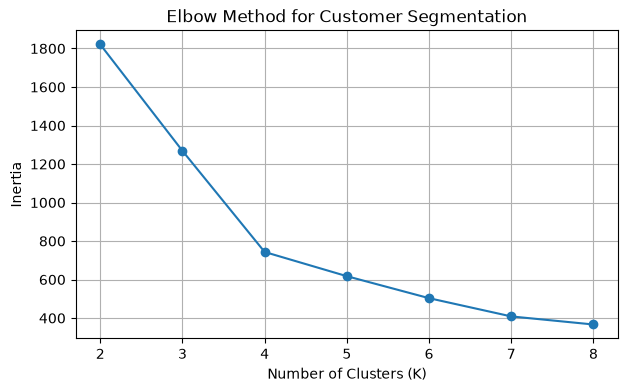

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    cluster_results_df["K"],
    cluster_results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(cluster_results_df["K"])
plt.grid(True)
plt.show()



### Observation

Inertia decreases as the number of clusters increases. However, choosing more clusters does not always make segmentation better, as too many groups may be difficult to manage.

Based on the elbow plot, silhouette scores and business needs, K = 4 is selected as a practical choice for customer segmentation.



### Customer Segment Profiling

selected K-Means model to group customers based on their RFM values. I will compare the average purchasing behaviour of each group to understand the differences between customer segments.


In [30]:

# Apply the final K-Means model with 4 clusters
final_kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

rfm["segment_id"] = final_kmeans.fit_predict(rfm_scaled)

# Summarise each customer segment
segment_profile = (
    rfm.groupby("segment_id")
    .agg(
        customer_count=("customer_id", "count"),
        mean_recency=("recency", "mean"),
        mean_frequency=("frequency", "mean"),
        mean_monetary=("monetary", "mean")
    )
    .round(2)
    .reset_index()
)

print("Customer segment profile:")
display(segment_profile)


Customer segment profile:


,segment_id,customer_count,mean_recency,mean_frequency,mean_monetary
0,0,436,28.86,3.77,1057.62
1,1,138,24.12,6.77,7129.70
2,2,419,8.77,19.40,3410.02
3,3,182,109.04,2.20,685.99


Understanding each customer segment

In [31]:

# Identify the segment with the highest average spending
premium_segment = segment_profile.loc[
    segment_profile["mean_monetary"].idxmax(),
    "segment_id"
]

# Display the segment selected as Premium
print("Premium segment ID:", premium_segment)

# Add business names and recommended actions
segment_details = {
    segment_id: {
        "segment_name": (
            "Premium Customers" if segment_id == premium_segment
            else "Regular Customers" if row["mean_frequency"] >= segment_profile["mean_frequency"].median()
            else "At-Risk Customers" if row["mean_recency"] >= segment_profile["mean_recency"].median()
            else "New or Occasional Customers"
        )
    }
    for _, row in segment_profile.iterrows()
    for segment_id in [row["segment_id"]]
}

# Display the segment names alongside their RFM profiles
segment_profile["segment_name"] = segment_profile["segment_id"].map(
    {key: value["segment_name"] for key, value in segment_details.items()}
)

print("Customer segments with business names:")
display(segment_profile)


Premium segment ID: 1
Customer segments with business names:


,segment_id,customer_count,mean_recency,mean_frequency,mean_monetary,segment_name
0,0,436,28.86,3.77,1057.62,At-Risk Customers
1,1,138,24.12,6.77,7129.70,Premium Customers
2,2,419,8.77,19.40,3410.02,Regular Customers
3,3,182,109.04,2.20,685.99,At-Risk Customers


Applying PCA to the scaled RFM data

In [32]:

from sklearn.decomposition import PCA

# Reduce the three RFM features to two principal components
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

# Display the variance explained by each component
pca_variance = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_.round(3)
})

print("PCA explained variance:")
display(pca_variance)

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 3)
)


PCA explained variance:


,Component,Explained Variance Ratio
0,PC1,0.634
1,PC2,0.218


Total variance explained: 0.852



### Final Customer Segment Analysis

compared the average RFM values of each group to understand customer behaviour. 


In [33]:

# Find the median values used to compare customer segments
recency_median = segment_profile["mean_recency"].median()
frequency_median = segment_profile["mean_frequency"].median()

# Assign a business name and action to each segment
segment_names = {}
segment_actions = {}

for _, row in segment_profile.iterrows():
    segment_id = row["segment_id"]

    if segment_id == premium_segment:
        name = "Premium Customers"
        action = "Offer loyalty rewards and exclusive deals."

    elif (
        row["mean_frequency"] >= frequency_median
        and row["mean_recency"] < recency_median
    ):
        name = "Loyal Customers"
        action = "Encourage repeat purchases with loyalty benefits."

    elif row["mean_recency"] >= recency_median:
        name = "At-Risk Customers"
        action = "Send personalised offers to encourage customers to return."

    else:
        name = "Occasional Customers"
        action = "Use product recommendations to increase purchases."

    segment_names[segment_id] = name
    segment_actions[segment_id] = action

# Update the customer segment profile
segment_profile["segment_name"] = segment_profile["segment_id"].map(segment_names)
segment_profile["recommended_action"] = segment_profile["segment_id"].map(segment_actions)

print("Final customer segment details:")
display(segment_profile)


Final customer segment details:


,segment_id,customer_count,mean_recency,mean_frequency,mean_monetary,segment_name,recommended_action
0,0,436,28.86,3.77,1057.62,At-Risk Customers,Send personalised offers to encourage customer...
1,1,138,24.12,6.77,7129.70,Premium Customers,Offer loyalty rewards and exclusive deals.
2,2,419,8.77,19.40,3410.02,Loyal Customers,Encourage repeat purchases with loyalty benefits.
3,3,182,109.04,2.20,685.99,At-Risk Customers,Send personalised offers to encourage customer...


PCA result

In [34]:

# Display the PCA explained variance
print("PCA explained variance ratio:")
display(pca_variance)

total_variance = pca.explained_variance_ratio_.sum()

print("Total variance explained:", round(total_variance, 3))
print("Premium segment ID:", premium_segment)


PCA explained variance ratio:


,Component,Explained Variance Ratio
0,PC1,0.634
1,PC2,0.218


Total variance explained: 0.852
Premium segment ID: 1


saving the final customer segments

In [35]:

# Add segment names and Premium status to the RFM table
rfm["segment_name"] = rfm["segment_id"].map(segment_names)
rfm["is_premium"] = rfm["segment_id"] == premium_segment

# Keep the columns required by the capstone
customer_segments = rfm[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "segment_id",
        "segment_name",
        "is_premium"
    ]
].copy()

# Create the output folder and save the results
output_folder = project_folder / "outputs"
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "customer_segments.csv"
customer_segments.to_csv(output_file, index=False)

print("Customer segmentation file saved successfully.")
print("File location:", output_file)
print("Total customer records:", len(customer_segments))

display(customer_segments.head())

# Check the required output
assert len(customer_segments) == 1175
assert customer_segments["is_premium"].sum() == (
    customer_segments["segment_id"] == premium_segment
).sum()

assert customer_segments.columns.tolist() == [
    "customer_id",
    "recency",
    "frequency",
    "monetary",
    "segment_id",
    "segment_name",
    "is_premium"
]

print("All customer segmentation checks passed.")


Customer segmentation file saved successfully.


File location: C:\Users\Lenovo\Desktop\Capstone_Project\outputs\customer_segments.csv
Total customer records: 1175


,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,At-Risk Customers,False
1,C0002,28,7,4644.90,1,Premium Customers,True
2,C0003,7,22,3644.85,2,Loyal Customers,False
3,C0004,0,5,369.00,0,At-Risk Customers,False
4,C0005,147,2,324.00,3,At-Risk Customers,False


All customer segmentation checks passed.



### Observation

The Premium group has the highest average spending. These segment details help the business plan suitable customer retention strategies.



### Preparing Customer Data for Lapse Prediction

- Identified customers who placed completed orders before September 1, 2025.
- Marked customers as lapsed if they made no completed orders during September.
- Prepared customer features using only data available before the cutoff date.


In [36]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Load the cleaned data
orders = pd.read_csv(project_folder / "data/clean/orders.csv")
customers = pd.read_csv(project_folder / "data/clean/customers.csv")
products = pd.read_csv(project_folder / "data/clean/products.csv")

orders["order_ts"] = pd.to_datetime(orders["order_ts"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
orders["status"] = orders["status"].str.strip().str.lower()

cutoff_date = pd.Timestamp("2025-09-01")
end_date = pd.Timestamp("2025-10-01")

# Orders before the cutoff are used for features
before_cutoff = orders[orders["order_ts"] < cutoff_date].copy()

completed = before_cutoff[
    before_cutoff["status"] == "completed"
].copy()

# Create the customer cohort
cohort_ids = completed["customer_id"].unique()

# Identify customers with completed orders during September
september_orders = orders[
    (orders["order_ts"] >= cutoff_date) &
    (orders["order_ts"] < end_date) &
    (orders["status"] == "completed")
]

active_customers = set(september_orders["customer_id"])

lapse_labels = pd.DataFrame({"customer_id": cohort_ids})
lapse_labels["lapsed"] = (
    ~lapse_labels["customer_id"].isin(active_customers)
).astype(int)

# Calculate customer purchase details
customer_features = (
    completed.groupby("customer_id")
    .agg(
        last_order_ts=("order_ts", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_amount", "sum"),
        avg_discount_pct=("discount_pct", "mean"),
        avg_delivery_minutes=("delivery_minutes", "mean")
    )
    .reset_index()
)

customer_features["recency"] = (
    cutoff_date - customer_features["last_order_ts"]
).dt.days

# Calculate cancellation rate
final_orders = before_cutoff[
    before_cutoff["status"].isin(["completed", "cancelled"])
].copy()

final_orders["cancelled"] = (
    final_orders["status"] == "cancelled"
).astype(int)

cancellation_rate = (
    final_orders.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=("cancelled", "sum")
    )
    .reset_index()
)

cancellation_rate["cancellation_rate"] = (
    cancellation_rate["cancelled_orders"] /
    cancellation_rate["total_orders"]
)

# Find the most frequently ordered product category
category_data = completed.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

favourite_category = (
    category_data.groupby(["customer_id", "category"])
    .size()
    .reset_index(name="count")
    .sort_values(
        ["customer_id", "count", "category"],
        ascending=[True, False, True]
    )
    .drop_duplicates("customer_id")
    [["customer_id", "category"]]
    .rename(columns={"category": "favourite_category"})
)

# Add customer details and calculated features
customer_features = customer_features.merge(
    cancellation_rate[["customer_id", "cancellation_rate"]],
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    favourite_category,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    customers[
        ["customer_id", "city", "age", "gender", "signup_date"]
    ],
    on="customer_id",
    how="left"
)

customer_features["tenure_days"] = (
    cutoff_date - customer_features["signup_date"]
).dt.days

# Combine features with lapse labels
lapse_data = customer_features.merge(
    lapse_labels,
    on="customer_id",
    how="inner"
)

# Select model features and target
feature_columns = [
    "recency", "frequency", "monetary",
    "avg_discount_pct", "cancellation_rate",
    "avg_delivery_minutes", "favourite_category",
    "city", "age", "gender", "tenure_days"
]

X = lapse_data[feature_columns].copy()
y = lapse_data["lapsed"].copy()

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Check baseline performance
baseline_predictions = [0] * len(y_test)

print("Total customers:", len(lapse_data))
print("Lapsed customers:", int(y.sum()))
print("Lapsed percentage:", round(y.mean() * 100, 2), "%")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nBaseline accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 3))

print("Baseline lapsed-class F1:",
      round(f1_score(y_test, baseline_predictions, zero_division=0), 3))

# Validate capstone reference values
assert len(lapse_data) == 1156
assert int(y.sum()) == 443
assert len(X_train) == 924
assert len(X_test) == 232

print("\nAll Task 4 checks passed.")


Total customers: 1156
Lapsed customers: 443
Lapsed percentage: 38.32 %
Training rows: 924
Testing rows: 232

Baseline accuracy: 0.616
Baseline lapsed-class F1: 0.0

All Task 4 checks passed.



### Data Preprocessing

- Checked the feature columns for missing values.
- Encoded categorical columns and scaled numerical columns.
- Fitted preprocessing on training data and applied it to testing data.


In [37]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical features
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount_pct",
    "cancellation_rate",
    "avg_delivery_minutes",
    "age",
    "tenure_days"
]

categorical_features = [
    "favourite_category",
    "city",
    "gender"
]

# Check for missing values before preprocessing
missing_values = X.isnull().sum()

print("Missing values in each feature:")
display(missing_values.to_frame("Missing Count"))

assert missing_values.sum() == 0, "Missing values found in model features."

# Set up preprocessing for both feature types
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

# Compare the frequency means
frequency_index = numeric_features.index("frequency")

training_frequency_mean = (
    preprocessor.named_transformers_["numeric"].mean_[frequency_index]
)

full_frequency_mean = X["frequency"].mean()

print("\nTraining frequency mean:", round(training_frequency_mean, 2))
print("Full cohort frequency mean:", round(full_frequency_mean, 2))

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully.")


Missing values in each feature:

,Missing Count
recency,0
frequency,0
monetary,0
avg_discount_pct,0
cancellation_rate,0
avg_delivery_minutes,0
favourite_category,0
city,0
age,0
gender,0



Training frequency mean: 8.11
Full cohort frequency mean: 8.03

Processed training shape: (924, 19)
Processed testing shape: (232, 19)

Preprocessing completed successfully.



### Model Training and Evaluation

- Tuned Logistic Regression and Random Forest using 5-fold cross-validation.
- Compared both models using the same test data.
- Evaluated how well each model identifies lapsed customers.


In [38]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Show the baseline for comparison
baseline_predictions = [0] * len(y_test)

print("Baseline Model")
print("Accuracy:", round(accuracy_score(y_test, baseline_predictions), 3))
print("Precision:", round(precision_score(
    y_test, baseline_predictions, zero_division=0
), 3))
print("Recall:", round(recall_score(
    y_test, baseline_predictions, zero_division=0
), 3))
print("F1-score:", round(f1_score(
    y_test, baseline_predictions, zero_division=0
), 3))


# Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={
        "model__C": [0.01, 0.1, 1, 10, 100]
    },
    cv=5,
    scoring="f1"
)

logistic_grid.fit(X_train, y_train)

print("\nLogistic Regression")
print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validation F1:", round(logistic_grid.best_score_, 3))


# Random Forest pipeline
forest_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

forest_grid = GridSearchCV(
    estimator=forest_pipeline,
    param_grid={
        "model__max_depth": [3, 5, 8],
        "model__min_samples_leaf": [5, 10, 20]
    },
    cv=5,
    scoring="f1"
)

forest_grid.fit(X_train, y_train)

print("\nRandom Forest")
print("Best parameters:", forest_grid.best_params_)
print("Best cross-validation F1:", round(forest_grid.best_score_, 3))


# Evaluate both tuned models on the untouched test data
models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "Random Forest": forest_grid.best_estimator_
}

evaluation_results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print(f"\n{model_name} - Test Results")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-score:", round(f1, 3))

    evaluation_results.append({
        "Model": model_name,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1-score": round(f1, 3)
    })

evaluation_table = pd.DataFrame(evaluation_results)

print("\nModel Comparison")
display(evaluation_table)

print("\nModel tuning and evaluation completed.")


Baseline Model
Accuracy: 0.616
Precision: 0.0
Recall: 0.0
F1-score: 0.0



Logistic Regression
Best parameters: {'model__C': 100}
Best cross-validation F1: 0.651



Random Forest
Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 10}
Best cross-validation F1: 0.687

Logistic Regression - Test Results
Confusion Matrix:
[[111  32]
 [ 31  58]]
Precision: 0.644
Recall: 0.652
F1-score: 0.648

Random Forest - Test Results
Confusion Matrix:
[[111  32]
 [ 32  57]]
Precision: 0.64
Recall: 0.64
F1-score: 0.64

Model Comparison


,Model,Precision,Recall,F1-score
0,Logistic Regression,0.644,0.652,0.648
1,Random Forest,0.640,0.640,0.640



Model tuning and evaluation completed.



### Class-Balance Experiment

- Balanced the training data by duplicating lapsed-customer records.
- Retrained the best Logistic Regression model using the balanced data.
- Compared precision, recall and F1-score on the original test data.


In [39]:

from sklearn.utils import resample

# Separate the two classes in the training data
lapsed_train = X_train[y_train == 1]
active_train = X_train[y_train == 0]

# Duplicate lapsed customers until both classes have equal counts
lapsed_oversampled = resample(
    lapsed_train,
    replace=True,
    n_samples=len(active_train),
    random_state=42
)

# Combine original training rows with the duplicated lapsed rows
X_train_balanced = pd.concat(
    [active_train, lapsed_train, lapsed_oversampled]
)

y_train_balanced = pd.concat([
    y_train.loc[active_train.index],
    y_train.loc[lapsed_train.index],
    pd.Series(
        1,
        index=lapsed_oversampled.index
    )
])

# Check the new class counts
print("Class counts after balancing:")
display(y_train_balanced.value_counts().sort_index())

# Refit the best Logistic Regression pipeline
balanced_logistic_model = logistic_grid.best_estimator_

balanced_logistic_model.fit(
    X_train_balanced,
    y_train_balanced
)

# Compare both models on the same original test data
original_predictions = logistic_grid.best_estimator_.predict(X_test)

balanced_predictions = balanced_logistic_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Original Logistic Regression", "Balanced Logistic Regression"],
    "Precision": [
        precision_score(y_test, original_predictions, zero_division=0),
        precision_score(y_test, balanced_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, original_predictions, zero_division=0),
        recall_score(y_test, balanced_predictions, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, original_predictions, zero_division=0),
        f1_score(y_test, balanced_predictions, zero_division=0)
    ]
})

comparison[["Precision", "Recall", "F1-score"]] = (
    comparison[["Precision", "Recall", "F1-score"]].round(3)
)

display(comparison)

print("Class-balance experiment completed.")


Class counts after balancing:


0    570
1    924
Name: count, dtype: int64

,Model,Precision,Recall,F1-score
0,Original Logistic Regression,0.563,0.955,0.708
1,Balanced Logistic Regression,0.563,0.955,0.708


Class-balance experiment completed.



### Model Interpretation and Retention List

- Reviewed the important features from Random Forest and Logistic Regression.
- Prepared a retention list of Premium customers with the highest predicted lapse probability.


In [40]:

import pandas as pd
import numpy as np
import joblib

# Select the model chosen in Task 6
selected_model = forest_grid.best_estimator_

# --------------------------------------------------
# 1. Random Forest: Top 5 important features
# --------------------------------------------------

best_forest = forest_grid.best_estimator_

feature_names = best_forest.named_steps[
    "preprocessing"
].get_feature_names_out()

importance_values = best_forest.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance", ascending=False
).head(5).reset_index(drop=True)

print("Top 5 Random Forest Features:")
display(feature_importance)


# --------------------------------------------------
# 2. Logistic Regression: Coefficient signs
# --------------------------------------------------

best_logistic = logistic_grid.best_estimator_

logistic_features = best_logistic.named_steps[
    "preprocessing"
].get_feature_names_out()

logistic_coefficients = best_logistic.named_steps[
    "model"
].coef_[0]

coefficient_table = pd.DataFrame({
    "Feature": logistic_features,
    "Coefficient": logistic_coefficients
})

# Show the coefficients of recency, frequency and monetary
selected_coefficients = coefficient_table[
    coefficient_table["Feature"].isin([
        "numeric__recency",
        "numeric__frequency",
        "numeric__monetary"
    ])
].copy()

selected_coefficients["Direction"] = np.where(
    selected_coefficients["Coefficient"] > 0,
    "Increases lapse likelihood",
    "Decreases lapse likelihood"
)

selected_coefficients["Coefficient"] = (
    selected_coefficients["Coefficient"].round(4)
)

print("\nLogistic Regression Coefficients:")
display(selected_coefficients)


# --------------------------------------------------
# 3. Save and reload the selected model
# --------------------------------------------------

output_folder = project_folder / "outputs"
output_folder.mkdir(exist_ok=True)

model_path = output_folder / "lapse_model.joblib"

# Save the selected model
joblib.dump(selected_model, model_path)

# Reload the saved model
reloaded_model = joblib.load(model_path)

# Verify predictions are identical
original_predictions = selected_model.predict(X_test)
reloaded_predictions = reloaded_model.predict(X_test)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
)

print("\nModel saved and reloaded successfully.")
print("Original and reloaded predictions match exactly.")


# --------------------------------------------------
# 4. Create the Premium customer retention list
# --------------------------------------------------

# Load the Premium segment information
segments = pd.read_csv(
    output_folder / "customer_segments.csv"
)

premium_ids = set(
    segments.loc[
        segments["is_premium"].astype(str).str.lower().isin(
            ["true", "1"]
        ),
        "customer_id"
    ]
)

# Keep customer IDs aligned with the original test rows
test_customers = lapse_data.loc[
    X_test.index, ["customer_id"]
].copy()

test_customers["actually_lapsed"] = y_test

# Select Premium customers from the test set
premium_test = test_customers[
    test_customers["customer_id"].isin(premium_ids)
].copy()

# Predict probability of lapse (class 1)
premium_probabilities = selected_model.predict_proba(
    X_test.loc[premium_test.index]
)[:, list(selected_model.classes_).index(1)]

premium_test["lapse_probability"] = premium_probabilities

# Rank customers by highest lapse probability
retention_list = (
    premium_test.sort_values(
        "lapse_probability",
        ascending=False
    )
    .head(10)
    [["customer_id", "lapse_probability", "actually_lapsed"]]
    .reset_index(drop=True)
)

retention_list["lapse_probability"] = (
    retention_list["lapse_probability"].round(4)
)

# Save the required CSV file
retention_list.to_csv(
    output_folder / "retention_list.csv",
    index=False
)

# Display results directly in the notebook
print("\nPremium Customer Retention List:")
display(retention_list)

actually_lapsed_count = int(
    retention_list["actually_lapsed"].sum()
)

print(
    "\nNumber of customers who actually lapsed:",
    actually_lapsed_count
)

print("\nTask 8 completed successfully.")


Top 5 Random Forest Features:


,Feature,Importance
0,numeric__monetary,0.277830
1,numeric__frequency,0.276787
2,numeric__recency,0.111219
3,numeric__avg_delivery_minutes,0.061649
4,numeric__avg_discount_pct,0.053178



Logistic Regression Coefficients:


,Feature,Coefficient,Direction
0,numeric__recency,0.0650,Increases lapse likelihood
1,numeric__frequency,-1.5364,Decreases lapse likelihood
2,numeric__monetary,0.2051,Increases lapse likelihood



Model saved and reloaded successfully.
Original and reloaded predictions match exactly.



Premium Customer Retention List:


,customer_id,lapse_probability,actually_lapsed
0,C0862,0.5304,0
1,C0060,0.4765,0
2,C1008,0.4756,0
3,C0267,0.4753,0
4,C0133,0.4712,0
5,C0942,0.4688,0
6,C1000,0.4654,0
7,C0553,0.4645,0
8,C1112,0.4620,0
9,C0565,0.4603,1



Number of customers who actually lapsed: 1

Task 8 completed successfully.
